In [ ]:
import pandas as pd, matplotlib.pyplot as plt

al = pd.read_csv("al_sde_split_grid.csv")
svts = pd.read_csv("svts_sde_split_grid.csv")


svts_sorted = svts.sort_values("Delta")
svts_sorted.to_csv("svts_sde_split_ranked_by_delta.csv", index=False)


print("\n=== SVTS+SDE split, ranked by Delta ===")
print(svts_sorted.to_string(index=False))
print("\nBest SVTS+SDE split (lowest Delta):")
print(svts_sorted.iloc[0])

plt.figure(figsize=(7,5))
plt.plot(al.AL_pct, al.Delta, marker='o')
plt.xlabel("AL% (SDE% = 10 - AL%)"); plt.ylabel("Delta")
plt.title("Hybrid AL+SDE: Delta vs Split")
plt.grid(alpha=0.3)
plt.savefig("al_sde_split_delta.png", dpi=200, bbox_inches='tight')
plt.close()

plt.figure(figsize=(8,5))
for a,b in [(1.0,0.0),(0.7,0.3),(0.5,0.5),(0.3,0.7),(0.0,1.0)]:
    sub = svts[(svts.alpha==a) & (svts.beta==b)]
    plt.plot(sub.SVTS_pct, sub.Delta, marker='o', label=f"alpha={a}, beta={b}")
plt.xlabel("SVTS% (SDE% = 10 - SVTS%)"); plt.ylabel("Delta")
plt.title("Hybrid SVTS+SDE: Delta vs Split, by alpha/beta")
plt.legend(); plt.grid(alpha=0.3)
plt.savefig("svts_sde_split_delta.png", dpi=200, bbox_inches='tight')
plt.close()

            Method  Converged_RMSD  Converged_Delta
                AL         1.54452          0.09440
  SDE (AL+SDE run)         1.44834          0.09008
  SVTS a=1.0 b=0.0         1.82752          0.11468
  SVTS a=0.7 b=0.3         1.57920          0.09622
  SVTS a=0.5 b=0.5         1.53406          0.09526
  SVTS a=0.3 b=0.7         1.54396          0.09504
  SVTS a=0.0 b=1.0         1.51424          0.09220
SDE (SVTS+SDE run)         1.40650          0.08800


In [3]:
import pandas as pd, matplotlib.pyplot as plt

MAX_N = 317  # point count equivalent to 10% budget (approx, varies slightly per path)

al = pd.read_csv("al_sde_split_grid.csv")
svts = pd.read_csv("svts_sde_split_grid.csv")

al["AL_pts"] = (al.AL_pct / 10 * MAX_N).round().astype(int)
al["SDE_pts"] = (al.SDE_pct / 10 * MAX_N).round().astype(int)
svts["SVTS_pts"] = (svts.SVTS_pct / 10 * MAX_N).round().astype(int)
svts["SDE_pts"] = (svts.SDE_pct / 10 * MAX_N).round().astype(int)

al_sorted = al.sort_values("Delta")
al_sorted.to_csv("al_sde_split_ranked_by_delta.csv", index=False)

svts_sorted = svts.sort_values("Delta")
svts_sorted.to_csv("svts_sde_split_ranked_by_delta.csv", index=False)

print("=== AL+SDE split, ranked by Delta ===")
print(al_sorted.to_string(index=False))
print("\nBest AL+SDE split (lowest Delta):")
print(al_sorted.iloc[0])

print("\n=== SVTS+SDE split, ranked by Delta ===")
print(svts_sorted.to_string(index=False))
print("\nBest SVTS+SDE split (lowest Delta):")
print(svts_sorted.iloc[0])

plt.figure(figsize=(7, 5))
plt.plot(al.AL_pts, al.Delta, marker="o")
plt.xlabel("AL training points (SDE points = total - AL)")
plt.ylabel("Delta")
plt.title("Hybrid AL+SDE: Delta vs AL point count")
plt.grid(alpha=0.3)
plt.savefig("al_sde_split_delta.png", dpi=200, bbox_inches="tight")
plt.close()

plt.figure(figsize=(8, 5))
for a, b in [(1.0, 0.0), (0.7, 0.3), (0.5, 0.5), (0.3, 0.7), (0.0, 1.0)]:
    sub = svts[(svts.alpha == a) & (svts.beta == b)]
    plt.plot(sub.SVTS_pts, sub.Delta, marker="o", label=f"alpha={a}, beta={b}")
plt.xlabel("SVTS training points (SDE points = total - SVTS)")
plt.ylabel("Delta")
plt.title("Hybrid SVTS+SDE: Delta vs SVTS point count, by alpha/beta")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig("svts_sde_split_delta.png", dpi=200, bbox_inches="tight")
plt.close()


=== AL+SDE split, ranked by Delta ===
 AL_pct  SDE_pct   RMSD  Delta  AL_pts  SDE_pts
      1        9 1.6598 0.0860      32      285
      2        8 1.6588 0.0861      63      254
      3        7 1.6613 0.0862      95      222
      4        6 1.6703 0.0862     127      190
      6        4 1.6789 0.0871     190      127
      9        1 1.6865 0.0874     285       32
      8        2 1.6800 0.0876     254       63
      7        3 1.6990 0.0878     222       95
      5        5 1.7230 0.0885     158      158

Best AL+SDE split (lowest Delta):
AL_pct       1.0000
SDE_pct      9.0000
RMSD         1.6598
Delta        0.0860
AL_pts      32.0000
SDE_pts    285.0000
Name: 0, dtype: float64

=== SVTS+SDE split, ranked by Delta ===
 SVTS_pct  SDE_pct  alpha  beta   RMSD  Delta  SVTS_pts  SDE_pts
        1        9    0.0   1.0 1.6533 0.0856        32      285
        3        7    0.5   0.5 1.6512 0.0858        95      222
        1        9    0.7   0.3 1.6641 0.0861        32      285
  

Saved svts_sde_split_delta.png


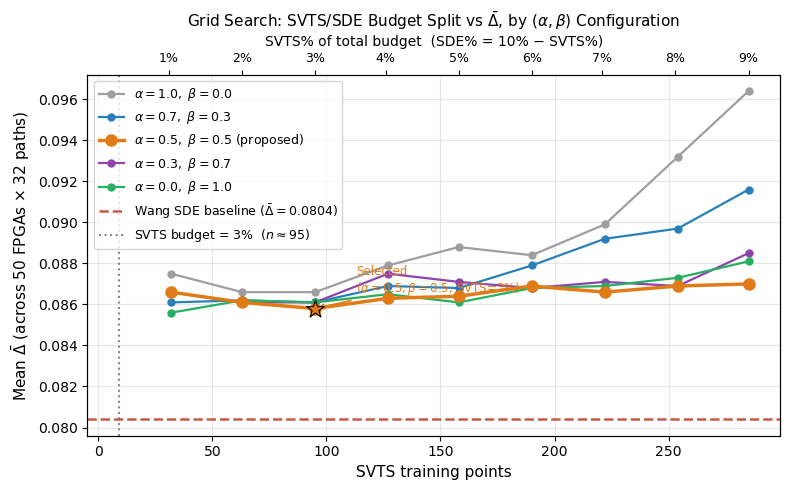

In [1]:
import pandas as pd, matplotlib.pyplot as plt

# svts_sde_split_grid.csv needs columns: SVTS_pct, SDE_pct, alpha, beta, Delta, SVTS_pts
# (generate with grid_search_svts.py or your existing split experiment)
svts = pd.read_csv("svts_sde_split_grid.csv")
MAX_N = 317
svts["SVTS_pts"] = (svts.SVTS_pct / 10 * MAX_N).round().astype(int)

WANG_SDE_DELTA = 0.0804  # reference baseline
BEST_ALPHA, BEST_BETA, BEST_PCT = 0.5, 0.5, 3  # selected operating point

COLORS = {
    (1.0, 0.0): "#9E9E9E",
    (0.7, 0.3): "#2980B9",
    (0.5, 0.5): "#E07B18",
    (0.3, 0.7): "#8E44AD",
    (0.0, 1.0): "#27AE60",
}
LWS = {(0.5, 0.5): 2.5}

fig, ax = plt.subplots(figsize=(8, 5))

for a, b in [(1.0, 0.0), (0.7, 0.3), (0.5, 0.5), (0.3, 0.7), (0.0, 1.0)]:
    sub = svts[(svts.alpha == a) & (svts.beta == b)].sort_values("SVTS_pts")
    lw = LWS.get((a, b), 1.6)
    ms = 8 if (a, b) == (0.5, 0.5) else 5
    ax.plot(
        sub.SVTS_pts,
        sub.Delta,
        color=COLORS[(a, b)],
        marker="o",
        linewidth=lw,
        markersize=ms,
        label=rf"$\alpha={a},\ \beta={b}$"
        + (" (proposed)" if (a, b) == (0.5, 0.5) else ""),
        zorder=6 if (a, b) == (0.5, 0.5) else 3,
    )

# Wang SDE reference
ax.axhline(
    y=WANG_SDE_DELTA,
    color="#C0392B",
    linestyle="--",
    linewidth=1.8,
    label=f"Wang SDE baseline ($\\bar{{\\Delta}}={WANG_SDE_DELTA}$)",
    alpha=0.85,
)

# Selected operating point marker
best_row = svts[
    (svts.alpha == BEST_ALPHA) & (svts.beta == BEST_BETA) & (svts.SVTS_pct == BEST_PCT)
]
if not best_row.empty:
    ax.scatter(
        best_row.SVTS_pts.values[0],
        best_row.Delta.values[0],
        color="#E07B18",
        s=180,
        zorder=10,
        marker="*",
        edgecolors="black",
        linewidths=0.8,
    )
    ax.annotate(
        f"Selected\n($\\alpha=0.5,\\beta=0.5$, SVTS=3%)",
        xy=(best_row.SVTS_pts.values[0], best_row.Delta.values[0]),
        xytext=(best_row.SVTS_pts.values[0] + 18, best_row.Delta.values[0] + 0.0008),
        fontsize=8.5,
        color="#E07B18",
        arrowprops=dict(arrowstyle="->", color="#E07B18", lw=1.2),
    )

# SVTS budget line at 3%
ax.axvline(
    x=int(0.03 * MAX_N),
    color="dimgray",
    linestyle=":",
    linewidth=1.5,
    label=r"SVTS budget = 3%  ($n\approx95$)",
    alpha=0.8,
)

# Top x-axis showing %
ax2 = ax.twiny()
ax2.set_xlim(ax.get_xlim())
ticks_pts = [int(p / 10 * MAX_N) for p in range(1, 10)]
ax2.set_xticks(ticks_pts)
ax2.set_xticklabels([f"{p}%" for p in range(1, 10)], fontsize=9)
ax2.set_xlabel("SVTS% of total budget  (SDE% = 10% − SVTS%)", fontsize=10)

ax.set_xlabel("SVTS training points", fontsize=11)
ax.set_ylabel(r"Mean $\bar{\Delta}$ (across 50 FPGAs × 32 paths)", fontsize=11)
ax.set_title(
    r"Grid Search: SVTS/SDE Budget Split vs $\bar{\Delta}$, by $(\alpha,\beta)$ Configuration",
    fontsize=11,
)
ax.legend(fontsize=9, loc="upper left")
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig("svts_sde_split_delta.png", dpi=200, bbox_inches="tight")
print("Saved svts_sde_split_delta.png")


Saved svts_sde_split_delta.png


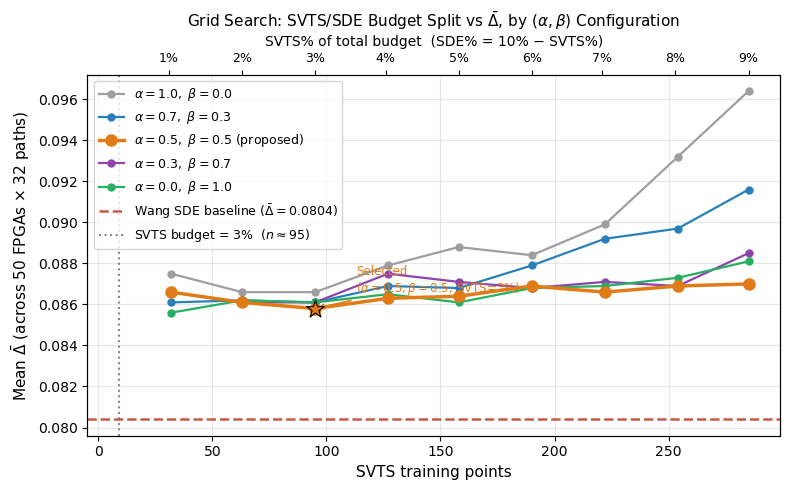

In [2]:
import pandas as pd, matplotlib.pyplot as plt

# svts_sde_split_grid.csv needs columns: SVTS_pct, SDE_pct, alpha, beta, Delta, SVTS_pts
# (generate with grid_search_svts.py or your existing split experiment)
svts = pd.read_csv("svts_sde_split_grid.csv")
MAX_N = 317
svts["SVTS_pts"] = (svts.SVTS_pct / 10 * MAX_N).round().astype(int)

WANG_SDE_DELTA = 0.0804  # reference baseline
BEST_ALPHA, BEST_BETA, BEST_PCT = 0.5, 0.5, 3  # selected operating point

COLORS = {
    (1.0, 0.0): "#9E9E9E",
    (0.7, 0.3): "#2980B9",
    (0.5, 0.5): "#E07B18",
    (0.3, 0.7): "#8E44AD",
    (0.0, 1.0): "#27AE60",
}
LWS = {(0.5, 0.5): 2.5}

fig, ax = plt.subplots(figsize=(8, 5))

for a, b in [(1.0, 0.0), (0.7, 0.3), (0.5, 0.5), (0.3, 0.7), (0.0, 1.0)]:
    sub = svts[(svts.alpha == a) & (svts.beta == b)].sort_values("SVTS_pts")
    lw = LWS.get((a, b), 1.6)
    ms = 8 if (a, b) == (0.5, 0.5) else 5
    ax.plot(
        sub.SVTS_pts,
        sub.Delta,
        color=COLORS[(a, b)],
        marker="o",
        linewidth=lw,
        markersize=ms,
        label=rf"$\alpha={a},\ \beta={b}$"
        + (" (proposed)" if (a, b) == (0.5, 0.5) else ""),
        zorder=6 if (a, b) == (0.5, 0.5) else 3,
    )

# Wang SDE reference
ax.axhline(
    y=WANG_SDE_DELTA,
    color="#C0392B",
    linestyle="--",
    linewidth=1.8,
    label=f"Wang SDE baseline ($\\bar{{\\Delta}}={WANG_SDE_DELTA}$)",
    alpha=0.85,
)

# Selected operating point marker
best_row = svts[
    (svts.alpha == BEST_ALPHA) & (svts.beta == BEST_BETA) & (svts.SVTS_pct == BEST_PCT)
]
if not best_row.empty:
    ax.scatter(
        best_row.SVTS_pts.values[0],
        best_row.Delta.values[0],
        color="#E07B18",
        s=180,
        zorder=10,
        marker="*",
        edgecolors="black",
        linewidths=0.8,
    )
    ax.annotate(
        f"Selected\n($\\alpha=0.5,\\beta=0.5$, SVTS=3%)",
        xy=(best_row.SVTS_pts.values[0], best_row.Delta.values[0]),
        xytext=(best_row.SVTS_pts.values[0] + 18, best_row.Delta.values[0] + 0.0008),
        fontsize=8.5,
        color="#E07B18",
        arrowprops=dict(arrowstyle="->", color="#E07B18", lw=1.2),
    )

# SVTS budget line at 3%
ax.axvline(
    x=int(0.03 * MAX_N),
    color="dimgray",
    linestyle=":",
    linewidth=1.5,
    label=r"SVTS budget = 3%  ($n\approx95$)",
    alpha=0.8,
)

# Top x-axis showing %
ax2 = ax.twiny()
ax2.set_xlim(ax.get_xlim())
ticks_pts = [int(p / 10 * MAX_N) for p in range(1, 10)]
ax2.set_xticks(ticks_pts)
ax2.set_xticklabels([f"{p}%" for p in range(1, 10)], fontsize=9)
ax2.set_xlabel("SVTS% of total budget  (SDE% = 10% − SVTS%)", fontsize=10)

ax.set_xlabel("SVTS training points", fontsize=11)
ax.set_ylabel(r"Mean $\bar{\Delta}$ (across 50 FPGAs × 32 paths)", fontsize=11)
ax.set_title(
    r"Grid Search: SVTS/SDE Budget Split vs $\bar{\Delta}$, by $(\alpha,\beta)$ Configuration",
    fontsize=11,
)
ax.legend(fontsize=9, loc="upper left")
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig("svts_sde_split_delta.png", dpi=200, bbox_inches="tight")
print("Saved svts_sde_split_delta.png")


Saved svts_sde_split_delta.pdf


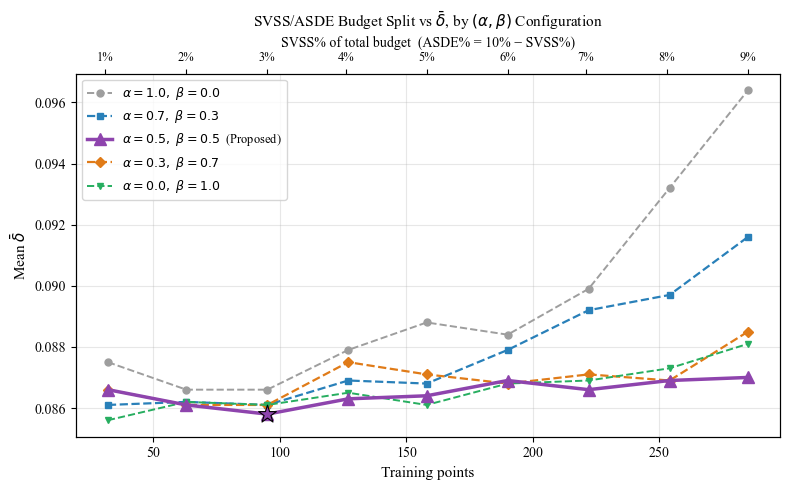

In [6]:
import pandas as pd, matplotlib.pyplot as plt

svts = pd.read_csv("svts_sde_split_grid.csv")
MAX_N = 317
svts["SVTS_pts"] = (svts.SVTS_pct / 10 * MAX_N).round().astype(int)

WANG_SDE_DELTA = 0.0804
BEST_ALPHA, BEST_BETA, BEST_PCT = 0.5, 0.5, 3

configs = [
    (1.0, 0.0, "#9E9E9E", "o", "--", 1.4, r"$\alpha=1.0,\ \beta=0.0$"),
    (0.7, 0.3, "#2980B9", "s", "--", 1.6, r"$\alpha=0.7,\ \beta=0.3$"),
    (0.5, 0.5, "#8E44AD", "^", "-", 2.5, r"$\alpha=0.5,\ \beta=0.5$  (Proposed)"),
    (0.3, 0.7, "#E07B18", "D", "--", 1.6, r"$\alpha=0.3,\ \beta=0.7$"),
    (0.0, 1.0, "#27AE60", "v", "--", 1.4, r"$\alpha=0.0,\ \beta=1.0$"),
]

fig, ax = plt.subplots(figsize=(8, 5))

for a, b, color, marker, ls, lw, label in configs:
    sub = svts[(svts.alpha == a) & (svts.beta == b)].sort_values("SVTS_pts")
    ms = 8 if (a, b) == (0.5, 0.5) else 5
    ax.plot(
        sub.SVTS_pts,
        sub.Delta,
        color=color,
        marker=marker,
        linestyle=ls,
        linewidth=lw,
        markersize=ms,
        label=label,
        zorder=6 if (a, b) == (0.5, 0.5) else 3,
    )



best_row = svts[
    (svts.alpha == BEST_ALPHA) & (svts.beta == BEST_BETA) & (svts.SVTS_pct == BEST_PCT)
]
if not best_row.empty:
    ax.scatter(
        best_row.SVTS_pts.values[0],
        best_row.Delta.values[0],
        color="#8E44AD",
        s=180,
        zorder=10,
        marker="*",
        edgecolors="black",
        linewidths=0.8,
    )


ax2 = ax.twiny()
ax2.set_xlim(ax.get_xlim())
ticks_pts = [int(p / 10 * MAX_N) for p in range(1, 10)]
ax2.set_xticks(ticks_pts)
ax2.set_xticklabels([f"{p}%" for p in range(1, 10)], fontsize=9,fontfamily="Times New Roman")
ax2.set_xlabel("SVSS% of total budget  (ASDE% = 10% − SVSS%)", fontsize=10,fontfamily="Times New Roman")

ax.set_xlabel("Training points", fontsize=11,fontfamily="Times New Roman")
ax.set_ylabel(r"Mean $\bar{δ}$", fontsize=11,fontfamily="Times New Roman")
ax.set_title(
    r"SVSS/ASDE Budget Split vs $\bar{δ}$, by $(\alpha,\beta)$ Configuration",
    fontsize=11,
)
ax.legend(fontsize=9, loc="upper left")
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig("svts_sde_split_delta.pdf", dpi=200, bbox_inches="tight")
print("Saved svts_sde_split_delta.pdf")


In [13]:
import os

os.environ["OMP_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"

import warnings, random, numpy as np, pandas as pd, GPy

warnings.filterwarnings("ignore")
GPy.util.linalg.jitchol_MAXTRIES = 20

ROOT_FOLDER = r"C:/Users/sysdp/OneDrive - 島根大学/Desktop/Research/FPGA DATA/Raw-data_exahaustive"
CALIB_FPGA = 1
NUM_PATHS = 1
TRAIN_RATIO = 0.10
SEED = 42

SVTS_ALPHA, SVTS_BETA = 0.7, 0.3
HYB_ALPHA, HYB_BETA = 0.5, 0.5
HYB_SVTS_RATIO = 0.03
K_NEIGHBORS = 2
ROUGHNESS_THRESH = 2.0
SDE_ALPHA, SDE_BETA = 2, 2


def load_dat(path):
    grid = np.loadtxt(path, delimiter=",")
    rows, cols = grid.shape
    rec = [
        (x, y, grid[y, x])
        for y in range(rows)
        for x in range(cols)
        if grid[y, x] != 0.0
    ]
    df = pd.DataFrame(rec, columns=["X", "Y", "Value"])
    med, std = df.Value.median(), df.Value.std()
    return df[np.abs(df.Value - med) <= 3 * std].reset_index(drop=True)


def evaluate(df, train_idx):
    X = df[["X", "Y"]].values.astype(float)
    Y = df["Value"].values.astype(float)
    test_idx = [i for i in range(len(df)) if i not in train_idx]
    m = GPy.models.GPRegression(
        X[train_idx], Y[train_idx].reshape(-1, 1), GPy.kern.RBF(2), normalizer=True
    )
    m.optimize(messages=False)
    pred, _ = m.predict(X[test_idx])
    true = Y[test_idx]
    rmsd = np.sqrt(np.mean((pred.flatten() - true) ** 2))
    dspec = Y.max() - Y.min()
    delta = np.mean(np.abs(pred.flatten() - true)) / dspec
    return rmsd, delta


def get_checkpoints(n_active):
    step = max(1, round(n_active * 0.01))
    n_train = int(n_active * TRAIN_RATIO)
    cps = sorted(set(min(step * i, n_train) for i in range(1, 11)))
    return step, n_train, cps


# ---------------- Raw AL (min-variance, matches raw_al.py) ----------------
def al_curve(df, n_train, checkpoints, rng):
    X = df[["X", "Y"]].values.astype(float)
    Y = df["Value"].values.astype(float)
    idx_all = np.arange(len(df))
    train_idx = [rng.choice(idx_all)]
    results = []
    while len(train_idx) < n_train:
        remaining = np.setdiff1d(idx_all, train_idx)
        m = GPy.models.GPRegression(
            X[train_idx], Y[train_idx].reshape(-1, 1), GPy.kern.RBF(2), normalizer=True
        )
        m.optimize(messages=False)
        _, var = m.predict(X[remaining])
        train_idx.append(remaining[np.argmin(var.ravel())])
        if len(train_idx) in checkpoints:
            r, d = evaluate(df, train_idx)
            results.append((len(train_idx), r, d))
    return results


# ---------------- SVTS growth (matches svts.py / hybrid_svts_sde.py's svts_select) ----------------
def svts_grow(df, target, rng, alpha, beta, checkpoints=None, results=None):
    X = df[["X", "Y"]].values.astype(float)
    Y = df["Value"].values.astype(float)
    idx_all = np.arange(len(df))
    train_idx = [rng.choice(idx_all)]
    if checkpoints is not None and len(train_idx) in checkpoints:
        r, d = evaluate(df, train_idx)
        results.append((len(train_idx), r, d))
    while len(train_idx) < target:
        remaining = np.setdiff1d(idx_all, train_idx)
        m = GPy.models.GPRegression(
            X[train_idx], Y[train_idx].reshape(-1, 1), GPy.kern.RBF(2), normalizer=True
        )
        m.optimize(messages=False)
        mean_r, var_r = m.predict(X[remaining])
        mean_s, var_s = m.predict(X[train_idx])
        all_mean = np.concatenate([mean_r.ravel(), mean_s.ravel()])
        all_var = np.concatenate([var_r.ravel(), var_s.ravel()])
        mean_z = (all_mean - all_mean.mean()) / (all_mean.std() + 1e-9)
        var_z = (all_var - all_var.mean()) / (all_var.std() + 1e-9)
        n_r = len(mean_r)
        feat_r = np.column_stack([mean_z[:n_r], var_z[:n_r]])
        feat_s = np.column_stack([mean_z[n_r:], var_z[n_r:]])
        centroid = feat_s.mean(axis=0)
        centroid_c = centroid - centroid.mean()
        feat_r_c = feat_r - feat_r.mean(axis=1, keepdims=True)
        sim = (feat_r_c @ centroid_c) / (
            np.linalg.norm(feat_r_c, axis=1) * np.linalg.norm(centroid_c) + 1e-9
        )
        sim_n = (sim - sim.min()) / (sim.max() - sim.min() + 1e-9)
        var_n = (var_r.ravel() - var_r.min()) / (var_r.max() - var_r.min() + 1e-9)
        score = alpha * sim_n + beta * var_n
        train_idx.append(remaining[np.argmax(score)])
        if checkpoints is not None and len(train_idx) in checkpoints:
            r, d = evaluate(df, train_idx)
            results.append((len(train_idx), r, d))
    return train_idx


def svts_curve(df, n_train, checkpoints, rng, alpha, beta):
    results = []
    svts_grow(df, n_train, rng, alpha, beta, checkpoints, results)
    return results


# ---------------- Raw SDE (fixed alpha=2,beta=2, matches sde.py, single shuffle) ----------------
def sde_curve(df, n_train, checkpoints, seed):
    idx_all = list(range(len(df)))
    random.Random(seed).shuffle(idx_all)
    train_idx = [idx_all[0]]
    results = []
    if len(train_idx) in checkpoints:
        r, d = evaluate(df, train_idx)
        results.append((len(train_idx), r, d))
    xs, ys = df.X.values, df.Y.values
    leftover = []
    for idx in idx_all[1:]:
        if len(train_idx) >= n_train:
            break
        if all(
            abs(xs[idx] - xs[s]) > SDE_ALPHA or abs(ys[idx] - ys[s]) > SDE_BETA
            for s in train_idx
        ):
            train_idx.append(idx)
            if len(train_idx) in checkpoints:
                r, d = evaluate(df, train_idx)
                results.append((len(train_idx), r, d))
        else:
            leftover.append(idx)
    if len(train_idx) < n_train:
        train_idx += leftover[: n_train - len(train_idx)]
        r, d = evaluate(df, train_idx)
        results.append((len(train_idx), r, d))
    return results


# ---------------- Adaptive SDE (matches hybrid_svts_sde.py's adaptive_sde exactly) ----------------
def adaptive_sde_grow(df, train_idx, n_train, seed, checkpoints=None, results=None):
    ab = {}
    for j in train_idx:
        xj, yj = df.loc[j, "X"], df.loc[j, "Y"]
        others = sorted(
            [p for p in train_idx if p != j],
            key=lambda p: (df.loc[p, "X"] - xj) ** 2 + (df.loc[p, "Y"] - yj) ** 2,
        )
        nn = others[:K_NEIGHBORS]
        if not nn:
            ab[j] = (1, 1)
            continue
        dx = np.mean([abs(df.loc[p, "X"] - xj) for p in nn])
        dy = np.mean([abs(df.loc[p, "Y"] - yj) for p in nn])
        bump = 1 if np.std([df.loc[p, "Value"] for p in nn]) > ROUGHNESS_THRESH else 0
        ab[j] = (int(np.ceil(dx)) + bump, int(np.ceil(dy)) + bump)
    default_ab = (
        int(np.mean([v[0] for v in ab.values()])),
        int(np.mean([v[1] for v in ab.values()])),
    )
    selected = list(train_idx)
    for i in np.random.RandomState(seed).permutation(df.index):
        if i in selected or len(selected) >= n_train:
            continue
        x, y = df.loc[i, "X"], df.loc[i, "Y"]
        if all(
            abs(df.loc[j, "X"] - x) > ab.get(j, default_ab)[0]
            or abs(df.loc[j, "Y"] - y) > ab.get(j, default_ab)[1]
            for j in selected
        ):
            selected.append(i)
            ab[i] = default_ab
            if checkpoints is not None and len(selected) in checkpoints:
                r, d = evaluate(df, selected)
                results.append((len(selected), r, d))
    if len(selected) < n_train:
        leftover = [
            i
            for i in np.random.RandomState(seed).permutation(df.index)
            if i not in selected
        ]
        selected += leftover[: n_train - len(selected)]
        if checkpoints is not None:
            r, d = evaluate(df, selected)
            results.append((len(selected), r, d))
    return selected


# ---------------- Hybrid SVTS+SDE (SVTS phase 3% then Adaptive SDE phase 7%) ----------------
def hybrid_curve(df, n_train, checkpoints, rng, alpha, beta, svts_ratio, seed):
    svts_target = max(1, round(len(df) * svts_ratio))
    results = []
    train_idx = svts_grow(df, svts_target, rng, alpha, beta, checkpoints, results)
    adaptive_sde_grow(df, train_idx, n_train, seed, checkpoints, results)
    return results


al_all, svts_all, sde_all, hyb_all = {}, {}, {}, {}
for path in range(1, NUM_PATHS + 1):
    df = load_dat(f"{ROOT_FOLDER}/FPGA-{CALIB_FPGA}/data{path}.dat")
    n_active = len(df)
    step, n_train, checkpoints = get_checkpoints(n_active)
    checkpoints = set(checkpoints)

    for n, r, d in al_curve(df, n_train, checkpoints, np.random.default_rng(SEED)):
        al_all.setdefault(n, []).append((r, d))
    for n, r, d in svts_curve(
        df, n_train, checkpoints, np.random.default_rng(SEED), SVTS_ALPHA, SVTS_BETA
    ):
        svts_all.setdefault(n, []).append((r, d))
    for n, r, d in sde_curve(df, n_train, checkpoints, SEED):
        sde_all.setdefault(n, []).append((r, d))
    for n, r, d in hybrid_curve(
        df,
        n_train,
        checkpoints,
        np.random.default_rng(SEED),
        HYB_ALPHA,
        HYB_BETA,
        HYB_SVTS_RATIO,
        SEED,
    ):
        hyb_all.setdefault(n, []).append((r, d))
    print(f"path {path} done (step={step}, n_train={n_train})")

for name, data in [
    ("Raw AL", al_all),
    ("SVTS (a=0.7,b=0.3)", svts_all),
    ("SDE", sde_all),
    ("Hybrid SVTS+SDE", hyb_all),
]:
    print(f"\n{name}")
    print(f"{'n_pts':>6} {'RMSD':>8} {'Delta':>8}")
    for n in sorted(data):
        rs = [x[0] for x in data[n]]
        ds = [x[1] for x in data[n]]
        print(f"{n:>6} {np.mean(rs):>8.4f} {np.mean(ds):>8.4f}")

path 1 done (step=32, n_train=315)

Raw AL
 n_pts     RMSD    Delta
    32   2.4583   0.2169
    64   2.4394   0.2152
    96   2.4443   0.2160
   128   2.4039   0.2122
   160   2.3696   0.2087
   192   2.3670   0.2085
   224   2.3526   0.2071
   256   2.3917   0.2114
   288   2.4493   0.2177
   315   2.4510   0.2182

SVTS (a=0.7,b=0.3)
 n_pts     RMSD    Delta
    32   2.2332   0.1938
    64   2.3749   0.2080
    96   2.3557   0.2062
   128   2.3430   0.2048
   160   2.2798   0.1987
   192   2.2469   0.1954
   224   2.2820   0.1987
   256   2.3152   0.2025
   288   2.2388   0.1941
   315   2.2593   0.1964

SDE
 n_pts     RMSD    Delta
    32   1.5703   0.1301
    64   1.2351   0.0996
    96   1.2064   0.0957
   128   1.2032   0.0960
   160   1.1769   0.0936
   192   1.1407   0.0924
   224   1.1444   0.0936
   256   1.1324   0.0920
   315   1.1334   0.0921

Hybrid SVTS+SDE
 n_pts     RMSD    Delta
    32   2.2332   0.1938
    64   2.3749   0.2080
    96   2.3269   0.2033
   128   1.2361

In [14]:
import pandas as pd, matplotlib.pyplot as plt

FILES = {
    "Raw AL": "raw_al.csv",
    "SVTS (a=0.7,b=0.3)": "svts.csv",
    "SDE": "sde.csv",
    "Hybrid SVTS+SDE": "hybrid_svts_sde.csv",
}

plt.figure(figsize=(9, 6))
for method, f in FILES.items():
    df = pd.read_csv(f)
    plt.plot(df.n_pts, df.Delta, marker="o", markersize=4, label=method)

plt.xlabel("Number of training points")
plt.ylabel("Delta")
plt.title("Convergence comparison: Raw AL, SVTS, SDE, Hybrid SVTS+SDE")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig("all_methods_convergence p1.png", dpi=200, bbox_inches="tight")
plt.close()
print("saved")


saved


In [24]:
import os

os.environ["OMP_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"

import warnings, random, numpy as np, pandas as pd, GPy

warnings.filterwarnings("ignore")
GPy.util.linalg.jitchol_MAXTRIES = 20

ROOT_FOLDER = r"C:/Users/sysdp/OneDrive - 島根大学/Desktop/Research/FPGA DATA/Raw-data_exahaustive"
OUT_CSV = r"C:/Users/sysdp/OneDrive - 島根大学/Desktop/Research/MY PAPERS/hybrid_svss_asde/plots/convergence_per_fpga.csv"
CALIB_FPGA = 1
FPGA_START, FPGA_END = 1, 50
NUM_PATHS = 32
TRAIN_RATIO = 0.10
SEED = 42

SVTS_ALPHA, SVTS_BETA = 0.7, 0.3
HYB_ALPHA, HYB_BETA = 0.5, 0.5
HYB_SVTS_RATIO = 0.03
K_NEIGHBORS = 2
ROUGHNESS_THRESH = 2.0
SDE_ALPHA, SDE_BETA = 2, 2


def load_dat(fpga, path):
    grid = np.loadtxt(f"{ROOT_FOLDER}/FPGA-{fpga}/data{path}.dat", delimiter=",")
    rows, cols = grid.shape
    rec = [
        (x, y, grid[y, x])
        for y in range(rows)
        for x in range(cols)
        if grid[y, x] != 0.0
    ]
    df = pd.DataFrame(rec, columns=["X", "Y", "Value"])
    med, std = df.Value.median(), df.Value.std()
    return df[np.abs(df.Value - med) <= 3 * std].reset_index(drop=True)


def get_checkpoints(n_active):
    step = max(1, round(n_active * 0.01))
    n_train = int(n_active * TRAIN_RATIO)
    return sorted(set(min(step * i, n_train) for i in range(1, 11)))


def al_checkpoints(df, n_train, checkpoints):
    X = df[["X", "Y"]].values.astype(float)
    Y = df["Value"].values.astype(float)
    idx_all = np.arange(len(df))
    rng = np.random.default_rng(SEED)
    train_idx = [rng.choice(idx_all)]
    out = {}
    while len(train_idx) < n_train:
        remaining = np.setdiff1d(idx_all, train_idx)
        m = GPy.models.GPRegression(
            X[train_idx], Y[train_idx].reshape(-1, 1), GPy.kern.RBF(2), normalizer=True
        )
        m.optimize(messages=False)
        _, var = m.predict(X[remaining])
        train_idx.append(remaining[np.argmin(var.ravel())])
        if len(train_idx) in checkpoints:
            out[len(train_idx)] = set(map(tuple, df.loc[train_idx, ["X", "Y"]].values))
    return out


def svts_single_grow(df, target, alpha, beta, checkpoints=None, out=None):
    rng = np.random.default_rng(SEED)
    X = df[["X", "Y"]].values.astype(float)
    Y = df["Value"].values.astype(float)
    idx_all = np.arange(len(df))
    train_idx = [rng.choice(idx_all)]
    if checkpoints is not None and len(train_idx) in checkpoints:
        out[len(train_idx)] = set(map(tuple, df.loc[train_idx, ["X", "Y"]].values))
    while len(train_idx) < target:
        remaining = np.setdiff1d(idx_all, train_idx)
        m = GPy.models.GPRegression(
            X[train_idx], Y[train_idx].reshape(-1, 1), GPy.kern.RBF(2), normalizer=True
        )
        m.optimize(messages=False)
        mean_r, var_r = m.predict(X[remaining])
        mean_s, var_s = m.predict(X[train_idx])
        all_mean = np.concatenate([mean_r.ravel(), mean_s.ravel()])
        all_var = np.concatenate([var_r.ravel(), var_s.ravel()])
        mean_z = (all_mean - all_mean.mean()) / (all_mean.std() + 1e-9)
        var_z = (all_var - all_var.mean()) / (all_var.std() + 1e-9)
        n_r = len(mean_r)
        feat_r = np.column_stack([mean_z[:n_r], var_z[:n_r]])
        feat_s = np.column_stack([mean_z[n_r:], var_z[n_r:]])
        centroid = feat_s.mean(axis=0)
        centroid_c = centroid - centroid.mean()
        feat_r_c = feat_r - feat_r.mean(axis=1, keepdims=True)
        sim = (feat_r_c @ centroid_c) / (
            np.linalg.norm(feat_r_c, axis=1) * np.linalg.norm(centroid_c) + 1e-9
        )
        sim_n = (sim - sim.min()) / (sim.max() - sim.min() + 1e-9)
        var_n = (var_r.ravel() - var_r.min()) / (var_r.max() - var_r.min() + 1e-9)
        score = alpha * sim_n + beta * var_n
        train_idx.append(remaining[np.argmax(score)])
        if checkpoints is not None and len(train_idx) in checkpoints:
            out[len(train_idx)] = set(map(tuple, df.loc[train_idx, ["X", "Y"]].values))
    return train_idx


def svts_checkpoints(df, n_train, checkpoints, alpha, beta):
    out = {}
    svts_single_grow(df, n_train, alpha, beta, checkpoints, out)
    return out


def sde_checkpoints(df, n_train, checkpoints):
    idx_all = list(range(len(df)))
    random.Random(SEED).shuffle(idx_all)
    train_idx = [idx_all[0]]
    out = {}
    if len(train_idx) in checkpoints:
        out[len(train_idx)] = set(map(tuple, df.loc[train_idx, ["X", "Y"]].values))
    xs, ys = df.X.values, df.Y.values
    leftover = []
    for idx in idx_all[1:]:
        if len(train_idx) >= n_train:
            break
        if all(
            abs(xs[idx] - xs[s]) > SDE_ALPHA or abs(ys[idx] - ys[s]) > SDE_BETA
            for s in train_idx
        ):
            train_idx.append(idx)
            if len(train_idx) in checkpoints:
                out[len(train_idx)] = set(
                    map(tuple, df.loc[train_idx, ["X", "Y"]].values)
                )
        else:
            leftover.append(idx)
    if len(train_idx) < n_train:
        train_idx += leftover[: n_train - len(train_idx)]
        out[len(train_idx)] = set(map(tuple, df.loc[train_idx, ["X", "Y"]].values))
    return out


# corrected: batch-based SVTS growth, matches hybrid_svts_sde.py's svts_select exactly
def svts_batch_grow(df, target, checkpoints=None, out=None):
    rng = np.random.default_rng(SEED)
    n = len(df)
    step = max(1, round(n * 0.01))
    X = df[["X", "Y"]].values.astype(float)
    Y = df["Value"].values.astype(float)
    train = list(rng.choice(n, size=step, replace=False))
    prev_len = 0
    while len(train) < target:
        remaining = [i for i in range(n) if i not in train]
        m = GPy.models.GPRegression(
            X[train], Y[train].reshape(-1, 1), GPy.kern.RBF(2), normalizer=True
        )
        m.optimize(messages=False)
        mean_r, var_r = m.predict(X[remaining])
        mean_s, var_s = m.predict(X[train])
        all_mean = np.concatenate([mean_r.ravel(), mean_s.ravel()])
        all_var = np.concatenate([var_r.ravel(), var_s.ravel()])
        mean_z = (all_mean - all_mean.mean()) / (all_mean.std() + 1e-9)
        var_z = (all_var - all_var.mean()) / (all_var.std() + 1e-9)
        n_r = len(mean_r)
        feat_r = np.column_stack([mean_z[:n_r], var_z[:n_r]])
        feat_s = np.column_stack([mean_z[n_r:], var_z[n_r:]])
        centroid = feat_s.mean(axis=0)
        centroid_c = centroid - centroid.mean()
        feat_r_c = feat_r - feat_r.mean(axis=1, keepdims=True)
        sim = (feat_r_c @ centroid_c) / (
            np.linalg.norm(feat_r_c, axis=1) * np.linalg.norm(centroid_c) + 1e-9
        )
        sim_n = (sim - sim.min()) / (sim.max() - sim.min() + 1e-9)
        var_n = (var_r.ravel() - var_r.min()) / (var_r.max() - var_r.min() + 1e-9)
        scores = HYB_ALPHA * sim_n + HYB_BETA * var_n
        pick = min(step, target - len(train), len(remaining))
        train += [remaining[i] for i in np.argsort(scores)[::-1][:pick]]
        if checkpoints is not None:
            for c in checkpoints:
                if prev_len < c <= len(train):
                    out[len(train)] = set(map(tuple, df.loc[train, ["X", "Y"]].values))
                    break
        prev_len = len(train)
    return train


def adaptive_sde_grow(df, train_idx, n_train, checkpoints=None, out=None):
    ab = {}
    for j in train_idx:
        xj, yj = df.loc[j, "X"], df.loc[j, "Y"]
        others = sorted(
            [p for p in train_idx if p != j],
            key=lambda p: (df.loc[p, "X"] - xj) ** 2 + (df.loc[p, "Y"] - yj) ** 2,
        )
        nn = others[:K_NEIGHBORS]
        if not nn:
            ab[j] = (1, 1)
            continue
        dx = np.mean([abs(df.loc[p, "X"] - xj) for p in nn])
        dy = np.mean([abs(df.loc[p, "Y"] - yj) for p in nn])
        bump = 1 if np.std([df.loc[p, "Value"] for p in nn]) > ROUGHNESS_THRESH else 0
        ab[j] = (int(np.ceil(dx)) + bump, int(np.ceil(dy)) + bump)
    default_ab = (
        int(np.mean([v[0] for v in ab.values()])),
        int(np.mean([v[1] for v in ab.values()])),
    )
    selected = list(train_idx)
    for i in np.random.RandomState(SEED).permutation(df.index):
        if i in selected or len(selected) >= n_train:
            continue
        x, y = df.loc[i, "X"], df.loc[i, "Y"]
        if all(
            abs(df.loc[j, "X"] - x) > ab.get(j, default_ab)[0]
            or abs(df.loc[j, "Y"] - y) > ab.get(j, default_ab)[1]
            for j in selected
        ):
            selected.append(i)
            ab[i] = default_ab
            if checkpoints is not None and len(selected) in checkpoints:
                out[len(selected)] = set(
                    map(tuple, df.loc[selected, ["X", "Y"]].values)
                )
    if len(selected) < n_train:
        leftover = [
            i
            for i in np.random.RandomState(SEED).permutation(df.index)
            if i not in selected
        ]
        selected += leftover[: n_train - len(selected)]
        out[len(selected)] = set(map(tuple, df.loc[selected, ["X", "Y"]].values))
    return selected


def hybrid_checkpoints(df, n_train, checkpoints):
    svts_target = max(1, round(len(df) * HYB_SVTS_RATIO))
    out = {}
    train_idx = svts_batch_grow(df, svts_target, checkpoints, out)
    adaptive_sde_grow(df, train_idx, n_train, checkpoints, out)
    return out


def evaluate_on_target(target_df, coord_set):
    X = target_df[["X", "Y"]].values.astype(float)
    Y = target_df["Value"].values.astype(float)
    coords = list(zip(target_df.X, target_df.Y))
    train_idx = [i for i, c in enumerate(coords) if c in coord_set]
    test_idx = [i for i in range(len(target_df)) if i not in train_idx]
    if len(train_idx) < 2 or len(test_idx) < 1:
        return None
    m = GPy.models.GPRegression(
        X[train_idx], Y[train_idx].reshape(-1, 1), GPy.kern.RBF(2), normalizer=True
    )
    m.optimize(messages=False)
    pred, _ = m.predict(X[test_idx])
    true = Y[test_idx]
    rmsd = np.sqrt(np.mean((pred.flatten() - true) ** 2))
    dspec = Y.max() - Y.min()
    delta = np.mean(np.abs(pred.flatten() - true)) / dspec
    return rmsd, delta


# ---- Step 1: calibration on CALIB_FPGA, once per path ----
calib = {"Raw AL": {}, "SVTS": {}, "SDE": {}, "Hybrid SVTS+SDE": {}}
for path in range(1, NUM_PATHS + 1):
    df = load_dat(CALIB_FPGA, path)
    n_active = len(df)
    checkpoints = set(get_checkpoints(n_active))
    n_train = int(n_active * TRAIN_RATIO)
    calib["Raw AL"][path] = al_checkpoints(df, n_train, checkpoints)
    calib["SVTS"][path] = svts_checkpoints(
        df, n_train, checkpoints, SVTS_ALPHA, SVTS_BETA
    )
    calib["SDE"][path] = sde_checkpoints(df, n_train, checkpoints)
    calib["Hybrid SVTS+SDE"][path] = hybrid_checkpoints(df, n_train, checkpoints)
    print(f"calibration done for path {path}")

# ---- Step 2: evaluate on every target FPGA, keep per-FPGA granularity ----
rows = []
target_fpgas = [f for f in range(FPGA_START, FPGA_END + 1) if f != CALIB_FPGA]

for fpga in target_fpgas:
    fpga_path_results = {name: {} for name in calib}
    for path in range(1, NUM_PATHS + 1):
        target_df = load_dat(fpga, path)
        for name in calib:
            for n_pts, coord_set in calib[name][path].items():
                out = evaluate_on_target(target_df, coord_set)
                if out is None:
                    continue
                r, d = out
                fpga_path_results[name].setdefault(n_pts, []).append((r, d))
    for name, data in fpga_path_results.items():
        for n_pts, vals in data.items():
            rs = [v[0] for v in vals]
            ds = [v[1] for v in vals]
            rows.append((name, fpga, n_pts, np.mean(rs), np.mean(ds), len(vals)))
    print(f"FPGA-{fpga} done")

result_df = pd.DataFrame(
    rows, columns=["Method", "FPGA", "n_pts", "RMSD", "Delta", "num_paths"]
)
result_df.to_csv(OUT_CSV, index=False)
print(f"\nsaved {OUT_CSV}, {len(result_df)} rows")


calibration done for path 1
calibration done for path 2
KeyboardInterrupt caught, calling on_optimization_end() to round things up


KeyboardInterrupt: 

In [19]:
import pandas as pd, matplotlib.pyplot as plt

CSV_PATH = r"C:/Users/sysdp/OneDrive - 島根大学/Desktop/Research/MY PAPERS/hybrid_svss_asde/plots/convergence_per_fpga.csv"

COLORS = {
    "AL": "#E74C3C",
    "SVTS": "#2ECC71",
    "SDE": "#3498DB",
    "Hybrid (Proposed)": "#9B59B6",
}
MARKERS = {"AL": "o", "SVTS": "s", "SDE": "D", "Hybrid (Proposed)": "^"}

# map dataset's method names to the display names used in COLORS/MARKERS
NAME_MAP = {
    "Raw AL": "AL",
    "SVTS": "SVTS",
    "SDE": "SDE",
    "Hybrid SVTS+SDE": "Hybrid (Proposed)",
}

df = pd.read_csv(CSV_PATH)
df = df[df.num_paths >= df.num_paths.max() * 0.9]

plt.figure(figsize=(9, 6))
for raw_name, display_name in NAME_MAP.items():
    sub = df[df.Method == raw_name]
    avg = sub.groupby("n_pts")["Delta"].mean().reset_index().sort_values("n_pts")
    std = sub.groupby("n_pts")["Delta"].std().reset_index().sort_values("n_pts")
    plt.plot(
        avg.n_pts,
        avg.Delta,
        marker=MARKERS[display_name],
        color=COLORS[display_name],
        markersize=6,
        linewidth=2,
        label=display_name,
    )
    plt.fill_between(
        avg.n_pts,
        avg.Delta - std.Delta,
        avg.Delta + std.Delta,
        color=COLORS[display_name],
        alpha=0.15,
    )

plt.xlabel("Number of training points")
plt.ylabel("Delta (mean ± std across FPGAs)")
plt.title("Convergence comparison across all FPGAs")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig("fpga_convergence_summary_styled.png", dpi=200, bbox_inches="tight")
plt.close()
print("saved")


saved


In [ ]:
import warnings, random, numpy as np, pandas as pd, GPy

warnings.filterwarnings("ignore")
GPy.util.linalg.jitchol_MAXTRIES = 20

ROOT_FOLDER = r"C:/Users/sysdp/OneDrive - 島根大学/Desktop/Research/FPGA DATA/Raw-data_exahaustive"
OUT_CSV = r"C:/Users/sysdp/OneDrive - 島根大学/Desktop/Research/MY PAPERS/Experiment/convergence_per_fpga.csv"
CALIB_FPGA = 1
FPGA_START, FPGA_END = 1, 50
NUM_PATHS = 32
TRAIN_RATIO = 0.10
SEED = 42

SVTS_ALPHA, SVTS_BETA = 0.7, 0.3
HYB_ALPHA, HYB_BETA = 0.5, 0.5
HYB_SVTS_RATIO = 0.03
K_NEIGHBORS = 2
ROUGHNESS_THRESH = 2.0
SDE_ALPHA, SDE_BETA = 2, 2


def load_dat(fpga, path):
    grid = np.loadtxt(f"{ROOT_FOLDER}/FPGA-{fpga}/data{path}.dat", delimiter=",")
    rows, cols = grid.shape
    rec = [
        (x, y, grid[y, x])
        for y in range(rows)
        for x in range(cols)
        if grid[y, x] != 0.0
    ]
    df = pd.DataFrame(rec, columns=["X", "Y", "Value"])
    med, std = df.Value.median(), df.Value.std()
    return df[np.abs(df.Value - med) <= 3 * std].reset_index(drop=True)


def get_checkpoints(n_active):
    step = max(1, round(n_active * 0.01))
    n_train = int(n_active * TRAIN_RATIO)
    return sorted(set(min(step * i, n_train) for i in range(1, 11)))


def al_checkpoints(df, n_train, checkpoints):
    X = df[["X", "Y"]].values.astype(float)
    Y = df["Value"].values.astype(float)
    idx_all = np.arange(len(df))
    rng = np.random.default_rng(SEED)
    train_idx = [rng.choice(idx_all)]
    out = {}
    while len(train_idx) < n_train:
        remaining = np.setdiff1d(idx_all, train_idx)
        m = GPy.models.GPRegression(
            X[train_idx], Y[train_idx].reshape(-1, 1), GPy.kern.RBF(2), normalizer=True
        )
        m.optimize(messages=False)
        _, var = m.predict(X[remaining])
        train_idx.append(remaining[np.argmin(var.ravel())])
        if len(train_idx) in checkpoints:
            out[len(train_idx)] = set(map(tuple, df.loc[train_idx, ["X", "Y"]].values))
    return out


def svts_single_grow(df, target, alpha, beta, checkpoints=None, out=None):
    rng = np.random.default_rng(SEED)
    X = df[["X", "Y"]].values.astype(float)
    Y = df["Value"].values.astype(float)
    idx_all = np.arange(len(df))
    train_idx = [rng.choice(idx_all)]
    if checkpoints is not None and len(train_idx) in checkpoints:
        out[len(train_idx)] = set(map(tuple, df.loc[train_idx, ["X", "Y"]].values))
    while len(train_idx) < target:
        remaining = np.setdiff1d(idx_all, train_idx)
        m = GPy.models.GPRegression(
            X[train_idx], Y[train_idx].reshape(-1, 1), GPy.kern.RBF(2), normalizer=True
        )
        m.optimize(messages=False)
        mean_r, var_r = m.predict(X[remaining])
        mean_s, var_s = m.predict(X[train_idx])
        all_mean = np.concatenate([mean_r.ravel(), mean_s.ravel()])
        all_var = np.concatenate([var_r.ravel(), var_s.ravel()])
        mean_z = (all_mean - all_mean.mean()) / (all_mean.std() + 1e-9)
        var_z = (all_var - all_var.mean()) / (all_var.std() + 1e-9)
        n_r = len(mean_r)
        feat_r = np.column_stack([mean_z[:n_r], var_z[:n_r]])
        feat_s = np.column_stack([mean_z[n_r:], var_z[n_r:]])
        centroid = feat_s.mean(axis=0)
        centroid_c = centroid - centroid.mean()
        feat_r_c = feat_r - feat_r.mean(axis=1, keepdims=True)
        sim = (feat_r_c @ centroid_c) / (
            np.linalg.norm(feat_r_c, axis=1) * np.linalg.norm(centroid_c) + 1e-9
        )
        sim_n = (sim - sim.min()) / (sim.max() - sim.min() + 1e-9)
        var_n = (var_r.ravel() - var_r.min()) / (var_r.max() - var_r.min() + 1e-9)
        score = alpha * sim_n + beta * var_n
        train_idx.append(remaining[np.argmax(score)])
        if checkpoints is not None and len(train_idx) in checkpoints:
            out[len(train_idx)] = set(map(tuple, df.loc[train_idx, ["X", "Y"]].values))
    return train_idx


def svts_checkpoints(df, n_train, checkpoints, alpha, beta):
    out = {}
    svts_single_grow(df, n_train, alpha, beta, checkpoints, out)
    return out


def sde_checkpoints(df, n_train, checkpoints):
    idx_all = list(range(len(df)))
    random.Random(SEED).shuffle(idx_all)
    train_idx = [idx_all[0]]
    out = {}
    if len(train_idx) in checkpoints:
        out[len(train_idx)] = set(map(tuple, df.loc[train_idx, ["X", "Y"]].values))
    xs, ys = df.X.values, df.Y.values
    leftover = []
    for idx in idx_all[1:]:
        if len(train_idx) >= n_train:
            break
        if all(
            abs(xs[idx] - xs[s]) > SDE_ALPHA or abs(ys[idx] - ys[s]) > SDE_BETA
            for s in train_idx
        ):
            train_idx.append(idx)
            if len(train_idx) in checkpoints:
                out[len(train_idx)] = set(
                    map(tuple, df.loc[train_idx, ["X", "Y"]].values)
                )
        else:
            leftover.append(idx)
    if len(train_idx) < n_train:
        train_idx += leftover[: n_train - len(train_idx)]
        out[len(train_idx)] = set(map(tuple, df.loc[train_idx, ["X", "Y"]].values))
    return out


# corrected: batch-based SVTS growth, matches hybrid_svts_sde.py's svts_select exactly
def svts_batch_grow(df, target, checkpoints=None, out=None):
    rng = np.random.default_rng(SEED)
    n = len(df)
    step = max(1, round(n * 0.01))
    X = df[["X", "Y"]].values.astype(float)
    Y = df["Value"].values.astype(float)
    train = list(rng.choice(n, size=step, replace=False))
    pending = (
        sorted([c for c in checkpoints if c <= target])
        if checkpoints is not None
        else []
    )

    def flush():
        while pending and len(train) >= pending[0]:
            c = pending.pop(0)
            out[c] = set(map(tuple, df.loc[train[:c], ["X", "Y"]].values))

    flush()
    while len(train) < target:
        remaining = [i for i in range(n) if i not in train]
        m = GPy.models.GPRegression(
            X[train], Y[train].reshape(-1, 1), GPy.kern.RBF(2), normalizer=True
        )
        m.optimize(messages=False)
        mean_r, var_r = m.predict(X[remaining])
        mean_s, var_s = m.predict(X[train])
        all_mean = np.concatenate([mean_r.ravel(), mean_s.ravel()])
        all_var = np.concatenate([var_r.ravel(), var_s.ravel()])
        mean_z = (all_mean - all_mean.mean()) / (all_mean.std() + 1e-9)
        var_z = (all_var - all_var.mean()) / (all_var.std() + 1e-9)
        n_r = len(mean_r)
        feat_r = np.column_stack([mean_z[:n_r], var_z[:n_r]])
        feat_s = np.column_stack([mean_z[n_r:], var_z[n_r:]])
        centroid = feat_s.mean(axis=0)
        centroid_c = centroid - centroid.mean()
        feat_r_c = feat_r - feat_r.mean(axis=1, keepdims=True)
        sim = (feat_r_c @ centroid_c) / (
            np.linalg.norm(feat_r_c, axis=1) * np.linalg.norm(centroid_c) + 1e-9
        )
        sim_n = (sim - sim.min()) / (sim.max() - sim.min() + 1e-9)
        var_n = (var_r.ravel() - var_r.min()) / (var_r.max() - var_r.min() + 1e-9)
        scores = HYB_ALPHA * sim_n + HYB_BETA * var_n
        pick = min(step, target - len(train), len(remaining))
        train += [remaining[i] for i in np.argsort(scores)[::-1][:pick]]
        flush()
    return train


def adaptive_sde_grow(df, train_idx, n_train, checkpoints=None, out=None):
    ab = {}
    for j in train_idx:
        xj, yj = df.loc[j, "X"], df.loc[j, "Y"]
        others = sorted(
            [p for p in train_idx if p != j],
            key=lambda p: (df.loc[p, "X"] - xj) ** 2 + (df.loc[p, "Y"] - yj) ** 2,
        )
        nn = others[:K_NEIGHBORS]
        if not nn:
            ab[j] = (1, 1)
            continue
        dx = np.mean([abs(df.loc[p, "X"] - xj) for p in nn])
        dy = np.mean([abs(df.loc[p, "Y"] - yj) for p in nn])
        bump = 1 if np.std([df.loc[p, "Value"] for p in nn]) > ROUGHNESS_THRESH else 0
        ab[j] = (int(np.ceil(dx)) + bump, int(np.ceil(dy)) + bump)
    default_ab = (
        int(np.mean([v[0] for v in ab.values()])),
        int(np.mean([v[1] for v in ab.values()])),
    )
    selected = list(train_idx)
    pending = (
        sorted([c for c in checkpoints if c <= n_train and c > 0])
        if checkpoints is not None
        else []
    )

    def flush():
        while pending and len(selected) >= pending[0]:
            c = pending.pop(0)
            out[c] = set(map(tuple, df.loc[selected[:c], ["X", "Y"]].values))

    flush()
    for i in np.random.RandomState(SEED).permutation(df.index):
        if i in selected or len(selected) >= n_train:
            continue
        x, y = df.loc[i, "X"], df.loc[i, "Y"]
        if all(
            abs(df.loc[j, "X"] - x) > ab.get(j, default_ab)[0]
            or abs(df.loc[j, "Y"] - y) > ab.get(j, default_ab)[1]
            for j in selected
        ):
            selected.append(i)
            ab[i] = default_ab
            flush()
    if len(selected) < n_train:
        leftover = [
            i
            for i in np.random.RandomState(SEED).permutation(df.index)
            if i not in selected
        ]
        selected += leftover[: n_train - len(selected)]
        flush()
    return selected


def hybrid_checkpoints(df, n_train, checkpoints):
    svts_target = max(1, round(len(df) * HYB_SVTS_RATIO))
    out = {}
    train_idx = svts_batch_grow(df, svts_target, checkpoints, out)
    adaptive_sde_grow(df, train_idx, n_train, checkpoints, out)
    return out


def evaluate_on_target(target_df, coord_set):
    X = target_df[["X", "Y"]].values.astype(float)
    Y = target_df["Value"].values.astype(float)
    coords = list(zip(target_df.X, target_df.Y))
    train_idx = [i for i, c in enumerate(coords) if c in coord_set]
    test_idx = [i for i in range(len(target_df)) if i not in train_idx]
    if len(train_idx) < 2 or len(test_idx) < 1:
        return None
    m = GPy.models.GPRegression(
        X[train_idx], Y[train_idx].reshape(-1, 1), GPy.kern.RBF(2), normalizer=True
    )
    m.optimize(messages=False)
    pred, _ = m.predict(X[test_idx])
    true = Y[test_idx]
    rmsd = np.sqrt(np.mean((pred.flatten() - true) ** 2))
    dspec = Y.max() - Y.min()
    delta = np.mean(np.abs(pred.flatten() - true)) / dspec
    return rmsd, delta


# ---- Step 1: calibration on CALIB_FPGA, once per path ----
calib = {"Raw AL": {}, "SVTS": {}, "SDE": {}, "Hybrid SVTS+SDE": {}}
for path in range(1, NUM_PATHS + 1):
    df = load_dat(CALIB_FPGA, path)
    n_active = len(df)
    checkpoints = set(get_checkpoints(n_active))
    n_train = int(n_active * TRAIN_RATIO)
    calib["Raw AL"][path] = al_checkpoints(df, n_train, checkpoints)
    calib["SVTS"][path] = svts_checkpoints(
        df, n_train, checkpoints, SVTS_ALPHA, SVTS_BETA
    )
    calib["SDE"][path] = sde_checkpoints(df, n_train, checkpoints)
    calib["Hybrid SVTS+SDE"][path] = hybrid_checkpoints(df, n_train, checkpoints)
    print(f"calibration done for path {path}")

# ---- Step 2: evaluate on every target FPGA, keep per-FPGA granularity ----
rows = []
target_fpgas = [f for f in range(FPGA_START, FPGA_END + 1) if f != CALIB_FPGA]

for fpga in target_fpgas:
    fpga_path_results = {name: {} for name in calib}
    for path in range(1, NUM_PATHS + 1):
        target_df = load_dat(fpga, path)
        for name in calib:
            for n_pts, coord_set in calib[name][path].items():
                out = evaluate_on_target(target_df, coord_set)
                if out is None:
                    continue
                r, d = out
                fpga_path_results[name].setdefault(n_pts, []).append((r, d))
    for name, data in fpga_path_results.items():
        for n_pts, vals in data.items():
            rs = [v[0] for v in vals]
            ds = [v[1] for v in vals]
            rows.append((name, fpga, n_pts, np.mean(rs), np.mean(ds), len(vals)))
    print(f"FPGA-{fpga} done")

result_df = pd.DataFrame(
    rows, columns=["Method", "FPGA", "n_pts", "RMSD", "Delta", "num_paths"]
)
result_df.to_csv(OUT_CSV, index=False)
print(f"\nsaved {OUT_CSV}, {len(result_df)} rows")


path 1 first checkpoint recomputed
path 2 first checkpoint recomputed
path 3 first checkpoint recomputed
path 4 first checkpoint recomputed
path 5 first checkpoint recomputed
path 6 first checkpoint recomputed
path 7 first checkpoint recomputed
path 8 first checkpoint recomputed
path 9 first checkpoint recomputed
path 10 first checkpoint recomputed
path 11 first checkpoint recomputed
path 12 first checkpoint recomputed
path 13 first checkpoint recomputed
path 14 first checkpoint recomputed
path 15 first checkpoint recomputed
path 16 first checkpoint recomputed
path 17 first checkpoint recomputed
path 18 first checkpoint recomputed
path 19 first checkpoint recomputed
path 20 first checkpoint recomputed
path 21 first checkpoint recomputed
path 22 first checkpoint recomputed
path 23 first checkpoint recomputed
path 24 first checkpoint recomputed
path 25 first checkpoint recomputed
path 26 first checkpoint recomputed
path 27 first checkpoint recomputed
path 28 first checkpoint recomputed
p

In [17]:
import os

os.environ["OMP_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"

import warnings, numpy as np, pandas as pd, GPy

warnings.filterwarnings("ignore")
GPy.util.linalg.jitchol_MAXTRIES = 20

ROOT_FOLDER = r"C:/Users/sysdp/OneDrive - 島根大学/Desktop/Research/FPGA DATA/Raw-data_exahaustive"
EXISTING_CSV = r"C:/Users/sysdp/OneDrive - 島根大学/Desktop/Research/MY PAPERS/hybrid_svss_asde/plots/convergence_per_fpga.csv"
CALIB_FPGA = 1
FPGA_START, FPGA_END = 1, 50
NUM_PATHS = 32
TRAIN_RATIO = 0.10
SEED = 42
HYB_ALPHA, HYB_BETA = 0.5, 0.5
HYB_SVTS_RATIO = 0.03
K_NEIGHBORS = 2
ROUGHNESS_THRESH = 2.0


def load_dat(fpga, path):
    grid = np.loadtxt(f"{ROOT_FOLDER}/FPGA-{fpga}/data{path}.dat", delimiter=",")
    rows, cols = grid.shape
    rec = [
        (x, y, grid[y, x])
        for y in range(rows)
        for x in range(cols)
        if grid[y, x] != 0.0
    ]
    df = pd.DataFrame(rec, columns=["X", "Y", "Value"])
    med, std = df.Value.median(), df.Value.std()
    return df[np.abs(df.Value - med) <= 3 * std].reset_index(drop=True)


def get_checkpoints(n_active):
    step = max(1, round(n_active * 0.01))
    n_train = int(n_active * TRAIN_RATIO)
    return sorted(set(min(step * i, n_train) for i in range(1, 11)))


def svts_batch_grow(df, target, checkpoints, out):
    rng = np.random.default_rng(SEED)
    n = len(df)
    step = max(1, round(n * 0.01))
    X = df[["X", "Y"]].values.astype(float)
    Y = df["Value"].values.astype(float)
    train = list(rng.choice(n, size=step, replace=False))
    pending = sorted([c for c in checkpoints if c <= target])

    def flush():
        while pending and len(train) >= pending[0]:
            c = pending.pop(0)
            out[c] = set(map(tuple, df.loc[train[:c], ["X", "Y"]].values))

    flush()
    while len(train) < target:
        remaining = [i for i in range(n) if i not in train]
        m = GPy.models.GPRegression(
            X[train], Y[train].reshape(-1, 1), GPy.kern.RBF(2), normalizer=True
        )
        m.optimize(messages=False)
        mean_r, var_r = m.predict(X[remaining])
        mean_s, var_s = m.predict(X[train])
        all_mean = np.concatenate([mean_r.ravel(), mean_s.ravel()])
        all_var = np.concatenate([var_r.ravel(), var_s.ravel()])
        mean_z = (all_mean - all_mean.mean()) / (all_mean.std() + 1e-9)
        var_z = (all_var - all_var.mean()) / (all_var.std() + 1e-9)
        n_r = len(mean_r)
        feat_r = np.column_stack([mean_z[:n_r], var_z[:n_r]])
        feat_s = np.column_stack([mean_z[n_r:], var_z[n_r:]])
        centroid = feat_s.mean(axis=0)
        centroid_c = centroid - centroid.mean()
        feat_r_c = feat_r - feat_r.mean(axis=1, keepdims=True)
        sim = (feat_r_c @ centroid_c) / (
            np.linalg.norm(feat_r_c, axis=1) * np.linalg.norm(centroid_c) + 1e-9
        )
        sim_n = (sim - sim.min()) / (sim.max() - sim.min() + 1e-9)
        var_n = (var_r.ravel() - var_r.min()) / (var_r.max() - var_r.min() + 1e-9)
        scores = HYB_ALPHA * sim_n + HYB_BETA * var_n
        pick = min(step, target - len(train), len(remaining))
        train += [remaining[i] for i in np.argsort(scores)[::-1][:pick]]
        flush()
    return train


def adaptive_sde_grow(df, train_idx, n_train, checkpoints, out):
    ab = {}
    for j in train_idx:
        xj, yj = df.loc[j, "X"], df.loc[j, "Y"]
        others = sorted(
            [p for p in train_idx if p != j],
            key=lambda p: (df.loc[p, "X"] - xj) ** 2 + (df.loc[p, "Y"] - yj) ** 2,
        )
        nn = others[:K_NEIGHBORS]
        if not nn:
            ab[j] = (1, 1)
            continue
        dx = np.mean([abs(df.loc[p, "X"] - xj) for p in nn])
        dy = np.mean([abs(df.loc[p, "Y"] - yj) for p in nn])
        bump = 1 if np.std([df.loc[p, "Value"] for p in nn]) > ROUGHNESS_THRESH else 0
        ab[j] = (int(np.ceil(dx)) + bump, int(np.ceil(dy)) + bump)
    default_ab = (
        int(np.mean([v[0] for v in ab.values()])),
        int(np.mean([v[1] for v in ab.values()])),
    )
    selected = list(train_idx)
    pending = sorted([c for c in checkpoints if c <= n_train and c > 0])

    def flush():
        while pending and len(selected) >= pending[0]:
            c = pending.pop(0)
            out[c] = set(map(tuple, df.loc[selected[:c], ["X", "Y"]].values))

    flush()
    for i in np.random.RandomState(SEED).permutation(df.index):
        if i in selected or len(selected) >= n_train:
            continue
        x, y = df.loc[i, "X"], df.loc[i, "Y"]
        if all(
            abs(df.loc[j, "X"] - x) > ab.get(j, default_ab)[0]
            or abs(df.loc[j, "Y"] - y) > ab.get(j, default_ab)[1]
            for j in selected
        ):
            selected.append(i)
            ab[i] = default_ab
            flush()
    if len(selected) < n_train:
        leftover = [
            i
            for i in np.random.RandomState(SEED).permutation(df.index)
            if i not in selected
        ]
        selected += leftover[: n_train - len(selected)]
        flush()
    return selected


def evaluate_on_target(target_df, coord_set):
    X = target_df[["X", "Y"]].values.astype(float)
    Y = target_df["Value"].values.astype(float)
    coords = list(zip(target_df.X, target_df.Y))
    train_idx = [i for i, c in enumerate(coords) if c in coord_set]
    test_idx = [i for i in range(len(target_df)) if i not in train_idx]
    if len(train_idx) < 2 or len(test_idx) < 1:
        return None
    m = GPy.models.GPRegression(
        X[train_idx], Y[train_idx].reshape(-1, 1), GPy.kern.RBF(2), normalizer=True
    )
    m.optimize(messages=False)
    pred, _ = m.predict(X[test_idx])
    true = Y[test_idx]
    rmsd = np.sqrt(np.mean((pred.flatten() - true) ** 2))
    dspec = Y.max() - Y.min()
    delta = np.mean(np.abs(pred.flatten() - true)) / dspec
    return rmsd, delta


# Step 1: recompute full Hybrid calibration per path, correctly, with all checkpoints filled
calib = {}
for path in range(1, NUM_PATHS + 1):
    df = load_dat(CALIB_FPGA, path)
    n_active = len(df)
    checkpoints = get_checkpoints(n_active)
    n_train = int(n_active * TRAIN_RATIO)
    svts_target = max(1, round(n_active * HYB_SVTS_RATIO))
    out = {}
    train_idx = svts_batch_grow(df, svts_target, checkpoints, out)
    adaptive_sde_grow(df, train_idx, n_train, checkpoints, out)
    calib[path] = out
    print(f"path {path} recalibrated, checkpoints: {sorted(out.keys())}")

# Step 2: evaluate on all target FPGAs, all checkpoints
target_fpgas = [f for f in range(FPGA_START, FPGA_END + 1) if f != CALIB_FPGA]
new_rows = []
for fpga in target_fpgas:
    results = {}
    for path in range(1, NUM_PATHS + 1):
        target_df = load_dat(fpga, path)
        for n_pts, coord_set in calib[path].items():
            out = evaluate_on_target(target_df, coord_set)
            if out is None:
                continue
            r, d = out
            results.setdefault(n_pts, []).append((r, d))
    for n_pts, vals in results.items():
        rs = [v[0] for v in vals]
        ds = [v[1] for v in vals]
        new_rows.append(
            ("Hybrid SVTS+SDE", fpga, n_pts, np.mean(rs), np.mean(ds), len(vals))
        )
    print(f"FPGA-{fpga} done")

new_df = pd.DataFrame(
    new_rows, columns=["Method", "FPGA", "n_pts", "RMSD", "Delta", "num_paths"]
)
existing = pd.read_csv(EXISTING_CSV)
existing = existing[
    existing.Method != "Hybrid SVTS+SDE"
]  # drop old, incomplete Hybrid rows
combined = pd.concat([existing, new_df], ignore_index=True)
combined = combined.sort_values(["Method", "FPGA", "n_pts"]).reset_index(drop=True)
combined.to_csv(EXISTING_CSV, index=False)
print(f"\nreplaced Hybrid SVTS+SDE rows, saved {len(combined)} total rows")


path 1 recalibrated, checkpoints: [32, 64, 96, 128, 160, 192, 224, 256, 288, 315]
path 2 recalibrated, checkpoints: [32, 64, 96, 128, 160, 192, 224, 256, 288, 317]
path 3 recalibrated, checkpoints: [32, 64, 96, 128, 160, 192, 224, 256, 288, 317]
path 4 recalibrated, checkpoints: [32, 64, 96, 128, 160, 192, 224, 256, 288, 317]
path 5 recalibrated, checkpoints: [32, 64, 96, 128, 160, 192, 224, 256, 288, 317]
path 6 recalibrated, checkpoints: [32, 64, 96, 128, 160, 192, 224, 256, 288, 317]
path 7 recalibrated, checkpoints: [32, 64, 96, 128, 160, 192, 224, 256, 288, 317]
path 8 recalibrated, checkpoints: [32, 64, 96, 128, 160, 192, 224, 256, 288, 317]
path 9 recalibrated, checkpoints: [32, 64, 96, 128, 160, 192, 224, 256, 288, 317]
path 10 recalibrated, checkpoints: [32, 64, 96, 128, 160, 192, 224, 256, 288, 317]
path 11 recalibrated, checkpoints: [32, 64, 96, 128, 160, 192, 224, 256, 288, 317]
path 12 recalibrated, checkpoints: [32, 64, 96, 128, 160, 192, 224, 256, 288, 317]
path 13 recal

In [2]:
import pandas as pd, matplotlib.pyplot as plt
import matplotlib

matplotlib.rcParams["font.family"] = "Times New Roman"
matplotlib.rcParams["pdf.fonttype"] = 42

CSV_PATH = r"C:/Users/sysdp/OneDrive - 島根大学/Desktop/Research/MY PAPERS/hybrid_svss_asde/plots/convergence_per_fpga.csv"

COLORS = {
    "AL": "#E74C3C",
    "SVTS": "#2ECC71",
    "SDE": "#3498DB",
    "Hybrid (Proposed)": "#9B59B6",
}
MARKERS = {"AL": "o", "SVTS": "s", "SDE": "D", "Hybrid (Proposed)": "^"}
LWS = {"AL": 1.4, "SVTS": 1.4, "SDE": 1.8, "Hybrid (Proposed)": 2.4}
NAME_MAP = {
    "Raw AL": "AL",
    "SVTS": "SVTS",
    "SDE": "SDE",
    "Hybrid SVTS+SDE": "Hybrid (Proposed)",
}

df = pd.read_csv(CSV_PATH)
df = df[df.num_paths >= df.num_paths.max() * 0.9]

fig, ax = plt.subplots(figsize=(12, 5))

for raw_name, display_name in NAME_MAP.items():
    sub = df[df.Method == raw_name]
    avg = sub.groupby("n_pts")["Delta"].mean().reset_index().sort_values("n_pts")
    std = sub.groupby("n_pts")["Delta"].std().reset_index().sort_values("n_pts")
    ax.plot(avg.n_pts, avg.Delta,
        marker=MARKERS[display_name], color=COLORS[display_name],
        linestyle='--',
        markersize=5, linewidth=LWS[display_name],
        label=display_name,
        zorder=5 if "Hybrid" in display_name else 3)
    ax.fill_between(
        avg.n_pts,
        avg.Delta - std.Delta,
        avg.Delta + std.Delta,
        color=COLORS[display_name],
        alpha=0.15,
    )
ax.axhline(0.09, color="gray", linestyle="--", linewidth=1.3, zorder=2)
ax.text(
    -0.01,
    0.09,
    "0.09",
    transform=ax.get_yaxis_transform(),
    color="gray",
    fontsize=9,
    va="center",
    ha="right",
)

ax.set_xlabel("Number of training points", fontsize=12)
ax.set_ylabel(r"Mean $\bar{δ}$ (± 1 Std across FPGAs)", fontsize=12)
ax.legend(fontsize=10)
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig("fpga_convergence_summary_styled.png", dpi=200, bbox_inches="tight")
fig.savefig("fpga_convergence_summary_styled.pdf", dpi=300, bbox_inches="tight")
plt.close()
print("saved")


saved


In [26]:
import os

os.environ["OMP_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"

import warnings, random, numpy as np, pandas as pd, GPy

warnings.filterwarnings("ignore")
GPy.util.linalg.jitchol_MAXTRIES = 20

ROOT_FOLDER = r"C:/Users/sysdp/OneDrive - 島根大学/Desktop/Research/FPGA DATA/Raw-data_exahaustive"
OUT_CSV = r"C:/Users/sysdp/OneDrive - 島根大学/Desktop/Research/MY PAPERS/hybrid_svss_asde/plots/convergence_per_fpga.csv"
CALIB_FPGA = 1
FPGA_START, FPGA_END = 1, 50
NUM_PATHS = 32
TRAIN_RATIO = 0.10
SEED = 42

SVTS_ALPHA, SVTS_BETA = 0.7, 0.3  # standalone SVTS (svts.py)
HYB_ALPHA, HYB_BETA = 0.5, 0.5  # hybrid's SVTS phase (hybrid_svts_sde.py)
HYB_SVTS_RATIO = 0.03  # hybrid's SVTS phase target (3% of budget)
K_NEIGHBORS = 2  # hybrid's adaptive SDE phase
ROUGHNESS_THRESH = 2.0
SDE_ALPHA, SDE_BETA = 2, 2  # standalone SDE (sde.py), fixed radius


def load_dat(fpga, path):
    grid = np.loadtxt(f"{ROOT_FOLDER}/FPGA-{fpga}/data{path}.dat", delimiter=",")
    rows, cols = grid.shape
    rec = [
        (x, y, grid[y, x])
        for y in range(rows)
        for x in range(cols)
        if grid[y, x] != 0.0
    ]
    df = pd.DataFrame(rec, columns=["X", "Y", "Value"])
    med, std = df.Value.median(), df.Value.std()
    return df[np.abs(df.Value - med) <= 3 * std].reset_index(drop=True)


def get_checkpoints(n_active):
    step = max(1, round(n_active * 0.01))
    n_train = int(n_active * TRAIN_RATIO)
    return sorted(set(min(step * i, n_train) for i in range(1, 11)))


# ---------------- Raw AL: min-variance, one point at a time ----------------
def al_checkpoints(df, n_train, checkpoints):
    X = df[["X", "Y"]].values.astype(float)
    Y = df["Value"].values.astype(float)
    idx_all = np.arange(len(df))
    rng = np.random.default_rng(SEED)
    train_idx = [rng.choice(idx_all)]
    out = {}
    while len(train_idx) < n_train:
        remaining = np.setdiff1d(idx_all, train_idx)
        m = GPy.models.GPRegression(
            X[train_idx], Y[train_idx].reshape(-1, 1), GPy.kern.RBF(2), normalizer=True
        )
        m.optimize(messages=False)
        _, var = m.predict(X[remaining])
        train_idx.append(remaining[np.argmin(var.ravel())])
        if len(train_idx) in checkpoints:
            out[len(train_idx)] = set(map(tuple, df.loc[train_idx, ["X", "Y"]].values))
    return out


# ---------------- Standalone SVTS: one point at a time (svts.py) ----------------
def svts_single_grow(df, target, alpha, beta, checkpoints=None, out=None):
    rng = np.random.default_rng(SEED)
    X = df[["X", "Y"]].values.astype(float)
    Y = df["Value"].values.astype(float)
    idx_all = np.arange(len(df))
    train_idx = [rng.choice(idx_all)]
    if checkpoints is not None and len(train_idx) in checkpoints:
        out[len(train_idx)] = set(map(tuple, df.loc[train_idx, ["X", "Y"]].values))
    while len(train_idx) < target:
        remaining = np.setdiff1d(idx_all, train_idx)
        m = GPy.models.GPRegression(
            X[train_idx], Y[train_idx].reshape(-1, 1), GPy.kern.RBF(2), normalizer=True
        )
        m.optimize(messages=False)
        mean_r, var_r = m.predict(X[remaining])
        mean_s, var_s = m.predict(X[train_idx])
        all_mean = np.concatenate([mean_r.ravel(), mean_s.ravel()])
        all_var = np.concatenate([var_r.ravel(), var_s.ravel()])
        mean_z = (all_mean - all_mean.mean()) / (all_mean.std() + 1e-9)
        var_z = (all_var - all_var.mean()) / (all_var.std() + 1e-9)
        n_r = len(mean_r)
        feat_r = np.column_stack([mean_z[:n_r], var_z[:n_r]])
        feat_s = np.column_stack([mean_z[n_r:], var_z[n_r:]])
        centroid = feat_s.mean(axis=0)
        centroid_c = centroid - centroid.mean()
        feat_r_c = feat_r - feat_r.mean(axis=1, keepdims=True)
        sim = (feat_r_c @ centroid_c) / (
            np.linalg.norm(feat_r_c, axis=1) * np.linalg.norm(centroid_c) + 1e-9
        )
        sim_n = (sim - sim.min()) / (sim.max() - sim.min() + 1e-9)
        var_n = (var_r.ravel() - var_r.min()) / (var_r.max() - var_r.min() + 1e-9)
        score = alpha * sim_n + beta * var_n
        train_idx.append(remaining[np.argmax(score)])
        if checkpoints is not None and len(train_idx) in checkpoints:
            out[len(train_idx)] = set(map(tuple, df.loc[train_idx, ["X", "Y"]].values))
    return train_idx


def svts_checkpoints(df, n_train, checkpoints, alpha, beta):
    out = {}
    svts_single_grow(df, n_train, alpha, beta, checkpoints, out)
    return out


# ---------------- Standalone SDE: fixed radius, single shuffle (sde.py) ----------------
def sde_checkpoints(df, n_train, checkpoints):
    idx_all = list(range(len(df)))
    random.Random(SEED).shuffle(idx_all)
    train_idx = [idx_all[0]]
    out = {}
    if len(train_idx) in checkpoints:
        out[len(train_idx)] = set(map(tuple, df.loc[train_idx, ["X", "Y"]].values))
    xs, ys = df.X.values, df.Y.values
    leftover = []
    for idx in idx_all[1:]:
        if len(train_idx) >= n_train:
            break
        if all(
            abs(xs[idx] - xs[s]) > SDE_ALPHA or abs(ys[idx] - ys[s]) > SDE_BETA
            for s in train_idx
        ):
            train_idx.append(idx)
            if len(train_idx) in checkpoints:
                out[len(train_idx)] = set(
                    map(tuple, df.loc[train_idx, ["X", "Y"]].values)
                )
        else:
            leftover.append(idx)
    if len(train_idx) < n_train:
        train_idx += leftover[: n_train - len(train_idx)]
        out[len(train_idx)] = set(map(tuple, df.loc[train_idx, ["X", "Y"]].values))
    return out


# ---------------- Hybrid's SVTS phase: batch growth (hybrid_svts_sde.py) ----------------
def svts_batch_grow(df, target, checkpoints=None, out=None):
    rng = np.random.default_rng(SEED)
    n = len(df)
    step = max(1, round(n * 0.01))
    X = df[["X", "Y"]].values.astype(float)
    Y = df["Value"].values.astype(float)
    train = list(rng.choice(n, size=step, replace=False))
    pending = (
        sorted([c for c in checkpoints if c <= target])
        if checkpoints is not None
        else []
    )

    def flush():
        while pending and len(train) >= pending[0]:
            c = pending.pop(0)
            out[c] = set(map(tuple, df.loc[train[:c], ["X", "Y"]].values))

    flush()
    while len(train) < target:
        remaining = [i for i in range(n) if i not in train]
        m = GPy.models.GPRegression(
            X[train], Y[train].reshape(-1, 1), GPy.kern.RBF(2), normalizer=True
        )
        m.optimize(messages=False)
        mean_r, var_r = m.predict(X[remaining])
        mean_s, var_s = m.predict(X[train])
        all_mean = np.concatenate([mean_r.ravel(), mean_s.ravel()])
        all_var = np.concatenate([var_r.ravel(), var_s.ravel()])
        mean_z = (all_mean - all_mean.mean()) / (all_mean.std() + 1e-9)
        var_z = (all_var - all_var.mean()) / (all_var.std() + 1e-9)
        n_r = len(mean_r)
        feat_r = np.column_stack([mean_z[:n_r], var_z[:n_r]])
        feat_s = np.column_stack([mean_z[n_r:], var_z[n_r:]])
        centroid = feat_s.mean(axis=0)
        centroid_c = centroid - centroid.mean()
        feat_r_c = feat_r - feat_r.mean(axis=1, keepdims=True)
        sim = (feat_r_c @ centroid_c) / (
            np.linalg.norm(feat_r_c, axis=1) * np.linalg.norm(centroid_c) + 1e-9
        )
        sim_n = (sim - sim.min()) / (sim.max() - sim.min() + 1e-9)
        var_n = (var_r.ravel() - var_r.min()) / (var_r.max() - var_r.min() + 1e-9)
        scores = HYB_ALPHA * sim_n + HYB_BETA * var_n
        pick = min(step, target - len(train), len(remaining))
        train += [remaining[i] for i in np.argsort(scores)[::-1][:pick]]
        flush()
    return train


# ---------------- Hybrid's SDE phase: adaptive per-point radius (hybrid_svts_sde.py) ----------------
def adaptive_sde_grow(df, train_idx, n_train, checkpoints=None, out=None):
    ab = {}
    for j in train_idx:
        xj, yj = df.loc[j, "X"], df.loc[j, "Y"]
        others = sorted(
            [p for p in train_idx if p != j],
            key=lambda p: (df.loc[p, "X"] - xj) ** 2 + (df.loc[p, "Y"] - yj) ** 2,
        )
        nn = others[:K_NEIGHBORS]
        if not nn:
            ab[j] = (1, 1)
            continue
        dx = np.mean([abs(df.loc[p, "X"] - xj) for p in nn])
        dy = np.mean([abs(df.loc[p, "Y"] - yj) for p in nn])
        bump = 1 if np.std([df.loc[p, "Value"] for p in nn]) > ROUGHNESS_THRESH else 0
        ab[j] = (int(np.ceil(dx)) + bump, int(np.ceil(dy)) + bump)
    default_ab = (
        int(np.mean([v[0] for v in ab.values()])),
        int(np.mean([v[1] for v in ab.values()])),
    )
    selected = list(train_idx)
    pending = (
        sorted([c for c in checkpoints if 0 < c <= n_train])
        if checkpoints is not None
        else []
    )

    def flush():
        while pending and len(selected) >= pending[0]:
            c = pending.pop(0)
            out[c] = set(map(tuple, df.loc[selected[:c], ["X", "Y"]].values))

    flush()
    for i in np.random.RandomState(SEED).permutation(df.index):
        if i in selected or len(selected) >= n_train:
            continue
        x, y = df.loc[i, "X"], df.loc[i, "Y"]
        if all(
            abs(df.loc[j, "X"] - x) > ab.get(j, default_ab)[0]
            or abs(df.loc[j, "Y"] - y) > ab.get(j, default_ab)[1]
            for j in selected
        ):
            selected.append(i)
            ab[i] = default_ab
            flush()
    if len(selected) < n_train:
        leftover = [
            i
            for i in np.random.RandomState(SEED).permutation(df.index)
            if i not in selected
        ]
        selected += leftover[: n_train - len(selected)]
        flush()
    return selected


def hybrid_checkpoints(df, n_train, checkpoints):
    svts_target = max(1, round(len(df) * HYB_SVTS_RATIO))
    out = {}
    train_idx = svts_batch_grow(df, svts_target, checkpoints, out)
    adaptive_sde_grow(df, train_idx, n_train, checkpoints, out)
    return out


def evaluate_on_target(target_df, coord_set):
    X = target_df[["X", "Y"]].values.astype(float)
    Y = target_df["Value"].values.astype(float)
    coords = list(zip(target_df.X, target_df.Y))
    train_idx = [i for i, c in enumerate(coords) if c in coord_set]
    test_idx = [i for i in range(len(target_df)) if i not in train_idx]
    if len(train_idx) < 2 or len(test_idx) < 1:
        return None
    m = GPy.models.GPRegression(
        X[train_idx], Y[train_idx].reshape(-1, 1), GPy.kern.RBF(2), normalizer=True
    )
    m.optimize(messages=False)
    pred, _ = m.predict(X[test_idx])
    true = Y[test_idx]
    rmsd = np.sqrt(np.mean((pred.flatten() - true) ** 2))
    dspec = Y.max() - Y.min()
    delta = np.mean(np.abs(pred.flatten() - true)) / dspec
    return rmsd, delta


# ==================== Step 1: calibration on CALIB_FPGA, once per path ====================
calib = {"Raw AL": {}, "SVTS": {}, "SDE": {}, "Hybrid SVTS+SDE": {}}
for path in range(1, NUM_PATHS + 1):
    df = load_dat(CALIB_FPGA, path)
    n_active = len(df)
    checkpoints = set(get_checkpoints(n_active))
    n_train = int(n_active * TRAIN_RATIO)
    calib["Raw AL"][path] = al_checkpoints(df, n_train, checkpoints)
    calib["SVTS"][path] = svts_checkpoints(
        df, n_train, checkpoints, SVTS_ALPHA, SVTS_BETA
    )
    calib["SDE"][path] = sde_checkpoints(df, n_train, checkpoints)
    calib["Hybrid SVTS+SDE"][path] = hybrid_checkpoints(df, n_train, checkpoints)
    print(f"calibration done for path {path}")

# ==================== Step 2: evaluate on every target FPGA ====================
rows = []
target_fpgas = [f for f in range(FPGA_START, FPGA_END + 1) if f != CALIB_FPGA]

for fpga in target_fpgas:
    fpga_path_results = {name: {} for name in calib}
    for path in range(1, NUM_PATHS + 1):
        target_df = load_dat(fpga, path)
        for name in calib:
            for n_pts, coord_set in calib[name][path].items():
                out = evaluate_on_target(target_df, coord_set)
                if out is None:
                    continue
                r, d = out
                fpga_path_results[name].setdefault(n_pts, []).append((r, d))
    for name, data in fpga_path_results.items():
        for n_pts, vals in data.items():
            rs = [v[0] for v in vals]
            ds = [v[1] for v in vals]
            rows.append((name, fpga, n_pts, np.mean(rs), np.mean(ds), len(vals)))
    print(f"FPGA-{fpga} done")

os.makedirs(os.path.dirname(OUT_CSV), exist_ok=True)
result_df = pd.DataFrame(
    rows, columns=["Method", "FPGA", "n_pts", "RMSD", "Delta", "num_paths"]
)
result_df.to_csv(OUT_CSV, index=False)
print(f"\nsaved {OUT_CSV}, {len(result_df)} rows")


calibration done for path 1
calibration done for path 2
calibration done for path 3
calibration done for path 4
calibration done for path 5
calibration done for path 6
calibration done for path 7
calibration done for path 8
calibration done for path 9
calibration done for path 10
calibration done for path 11
calibration done for path 12
calibration done for path 13
calibration done for path 14
calibration done for path 15
calibration done for path 16
calibration done for path 17
calibration done for path 18
calibration done for path 19
calibration done for path 20
calibration done for path 21
calibration done for path 22
calibration done for path 23
calibration done for path 24
calibration done for path 25
calibration done for path 26
calibration done for path 27
calibration done for path 28
calibration done for path 29
calibration done for path 30
calibration done for path 31
calibration done for path 32
FPGA-2 done
FPGA-3 done
FPGA-4 done
FPGA-5 done
FPGA-6 done
FPGA-7 done
FPGA-8 do

In [1]:
import pandas as pd, matplotlib.pyplot as plt
import matplotlib

matplotlib.rcParams["font.family"] = "Times New Roman"
matplotlib.rcParams["pdf.fonttype"] = 42

CSV_PATH = r"C:/Users/sysdp/OneDrive - 島根大学/Desktop/Research/MY PAPERS/hybrid_svss_asde/plots/convergence_per_fpga.csv"

COLORS = {
    "AL": "#E74C3C",
    "SVTS": "#2ECC71",
    "SDE": "#3498DB",
    "Hybrid (Proposed)": "#9B59B6",
}
MARKERS = {"AL": "o", "SVTS": "s", "SDE": "D", "Hybrid (Proposed)": "^"}
LWS = {"AL": 1.4, "SVTS": 1.4, "SDE": 1.8, "Hybrid (Proposed)": 2.4}
NAME_MAP = {
    "Raw AL": "AL",
    "SVTS": "SVTS",
    "SDE": "SDE",
    "Hybrid SVTS+SDE": "Hybrid (Proposed)",
}

TARGET = 0.09
ZOOM_XMIN, ZOOM_XMAX = 20, 200
ZOOM_YMIN, ZOOM_YMAX = 0.075, 0.115

df = pd.read_csv(CSV_PATH)
df = df[df.num_paths >= df.num_paths.max() * 0.9]

fig, ax = plt.subplots(figsize=(7, 4.5))

for raw_name, display_name in NAME_MAP.items():
    sub = df[df.Method == raw_name]
    avg = sub.groupby("n_pts")["Delta"].mean().reset_index().sort_values("n_pts")
    std = sub.groupby("n_pts")["Delta"].std().reset_index().sort_values("n_pts")
    ax.plot(
        avg.n_pts,
        avg.Delta,
        marker=MARKERS[display_name],
        color=COLORS[display_name],
        linestyle="--",
        markersize=6,
        linewidth=LWS[display_name],
        zorder=5 if "Hybrid" in display_name else 3,
    )
    ax.fill_between(
        avg.n_pts,
        avg.Delta - std.Delta,
        avg.Delta + std.Delta,
        color=COLORS[display_name],
        alpha=0.15,
    )

ax.axhline(TARGET, color="gray", linestyle="--", linewidth=1.5, zorder=2)

ax.set_xlim(ZOOM_XMIN, ZOOM_XMAX)
ax.set_ylim(ZOOM_YMIN, ZOOM_YMAX)
ax.set_xticks([50, 100, 150])
ax.set_yticks([0.08, TARGET, 0.10])

for tick, label in zip(ax.get_yticklabels(), [0.08, TARGET, 0.10]):
    if label == TARGET:
        tick.set_color("gray")

ax.set_xlabel("Number of training points", fontsize=12)
ax.set_ylabel(r"Mean $\bar{\delta}$ (± 1 Std across FPGAs)", fontsize=12)
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig("fpga_convergence_zoom.png", dpi=200, bbox_inches="tight")
fig.savefig("fpga_convergence_zoom.pdf", dpi=300, bbox_inches="tight")
plt.close()
print("saved")


saved
